지난시간 복습 

### 검색 Tool이 필요한 이유
- LLM의 파라미터에 담긴 지식으 최신 사실을 보장하지 않음
- 그렇기 때문에 웹 검색 도구는 외부 자료를 가져오는 역할을 함
- 다만 검색 결과 자체가 틀리거나 악성 지시를 포함할 수 있으므로 신뢰할 수 있는 출처와 날짜를 확인해야함

```
내부적으로 어떻게 사용되는가?
사용자 → LLM → 검색 필요? → 아니오 → LLM 응답
                        → 예 → 검색 Tool 사용 → 검색 결과 확인 → LLM 응답

```
___

LLM에서 검색이 필요하다 생각했을 떄 해당 검색으 툴로 제공하는 사이트 https://www.tavily.com/

API Key 발급받아 사용하면 됨 : 나는 Agent 이름으로 Key 발급받아 사용
___

# **1. TAVILY란?**
- AI 애플리케이션과 Agent가 웹에서 정보를 검색하고, 검색 결과의 제목/주소/본문의 일부를 구조화된 데이터로 받도록 지원하는 검색 API 서비스

```
우리가 쓰는 GPT가 있는데 TAVILY 왜 써?
토큰이 무제한 제공된다면 GPT 쓰면 되지만 이건 다 비용이 듦
특히 모든걸 API 연결해서 사용할 수 없음
```

In [50]:
import os
from dotenv import load_dotenv

In [51]:
load_dotenv()

OPENAI_API_KEY = bool(os.getenv("OPENAI_API_KEY"))
TAVILY_API_KEY = bool(os.getenv("TAVILY_API_KEY"))
OPENAI_MODEL = bool(os.getenv("OPENAI_MODEL"))

print("OPENAI_API_KEY:", OPENAI_API_KEY)
print("TAVILY_API_KEY:", TAVILY_API_KEY)
print("OPENAI_MODEL:", OPENAI_MODEL)

OPENAI_API_KEY: True
TAVILY_API_KEY: True
OPENAI_MODEL: True


In [52]:
# 위에서 모델을 bool타입으로 받아와서 실제 모델 이름을 가져오기 위해 사용

# 요거 안하면 def make_llm():에서 OPENAI_MODEL이 bool타입이라 제대로 모델을 가져오지 못함
MODEL_NAME = os.getenv("OPENAI_MODEL", "gpt-6-luna")

In [53]:
from langchain_openai import ChatOpenAI

In [54]:
def make_llm():
    if not OPENAI_API_KEY:
        print("KEY ERROR!")
        return None
    return ChatOpenAI(
        model=MODEL_NAME,
        reasoning_effort="none",
        timeout=30,
        max_retries=2, # 요청 실패 시 재시도 횟수
        temperature=0
    )

In [55]:
llm = make_llm()

In [56]:
# pip install tavily
from tavily import TavilyClient

In [57]:
if TAVILY_API_KEY:
    # 클라이언트 객체 생성
    tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))
    # API 호출, 검색 수행
    # max_results=3 : 검색결과 최대 3개
    raw_search = tavily_client.search(query="랭그래프는 뭐야?", max_results=3)
    print("최상위 키: ", list(raw_search.keys()))

    for idx, item in enumerate(raw_search.get("results", []), start=1):
        print(f"\n[{idx}] 제목: {item.get('title', '')}")
        print(f"주소: {item.get('url', '')}")
        print(f"요약: {str(item.get('content', ''))[:200]}")
else:
    print("TAVILY_API_KEY가 설정되지 않았습니다.")


최상위 키:  ['query', 'follow_up_questions', 'answer', 'images', 'results', 'response_time', 'request_id']

[1] 제목: LangGraph란 무엇이고 언제 쓰면 좋을까?
주소: https://velog.io/@ohback/LangGraph
요약: 여기서 등장하는 게 LangGraph다. 이름 그대로 그래프(노드/엣지)로 LLM 애플리케이션의 흐름을 설계한다.  
 LangChain이 블록(모델·프롬프트·툴)을 잘 조립하게 해주는 공구상자라면, LangGraph는 그 블록들이 언제, 어떤 조건으로, 어떤 상태를 들고 움직일지를 정밀하게 오케스트레이션하는 조감도 + 신호등에 가깝다.

  

## 그래

[2] 제목: 꿈 많은 사람의 이야기
주소: https://lsjsj92.tistory.com/696
요약: ## LangGraph란?

LangGraph는 LLM을 기반으로 상태를 유지하고(Stateful), 여러 단계에 걸쳐 작동하는(multi-step) 에이전트를 구축하기 위한 라이브러리입니다. 기존의 LangChain이 LLM과 외부 도구를 '연쇄적으로(chaining)' 연결하는 데 중점을 두었다면, LangGraph는 이러한 연결 구조를 순환(cycle

[3] 제목: 23화 22. LangGraph 기본과 응용
주소: https://brunch.co.kr/@aideveloper/132
요약: # 22. LangGraph 기본과 응용

LLM 시대, LangChain(랭체인)으로 배우는 AI 소프트웨어 개발

gaebalai-blog_ai-v3-1.jpg

## (1) LangGraph(랭그래프)란?

LangGraph(랭그래프)는 LangChain(랭체인)을 기반으로 하는 에이전트 프레임워크입니다. LangGraph(랭그래프)의 주요 특징은 복


### **1-1. 전체적인 API 흐름 만들기**

In [58]:
from langgraph.graph import StateGraph, START, END
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
# pip install langchain_tavily
from langchain_tavily import TavilySearch

In [59]:
if llm is not None and TAVILY_API_KEY:
    search_tool = TavilySearch(max_results=3)
    search_llm = llm.bind_tools([search_tool])

    def search_agent_node(state: MessagesState):
        response = search_llm.invoke(state["messages"])
        return {"messages": response}

    # 워크플로우 생성
    search_builder = StateGraph(MessagesState)
    search_builder.add_node("agent", search_agent_node)
    search_builder.add_node("tools", ToolNode([search_tool]))

    search_builder.add_edge(START, "agent")
    search_builder.add_conditional_edges("agent", tools_condition)
    search_builder.add_edge("tools", "agent")

    search_graph = search_builder.compile()

    # 확인
    result = search_graph.invoke(
        {"messages": [{"role": "user", "content": "LangGraph 최신 공식 문서를 찾아줘"}]},
        config={"recursion_limit": 10}
    )

    for message in result["messages"]:
        print(type(message).__name__, str(message.content)[:500])

else:
    print("LLM 또는 TAVILY_API_KEY가 설정되지 않았습니다.")

HumanMessage LangGraph 최신 공식 문서를 찾아줘
AIMessage 
ToolMessage {"query": "LangGraph official documentation latest LangChain docs", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://docs.langchain.com", "title": "Home - Docs by LangChain", "content": "Join the builders, engineers, and teams shaping what's next for agents. [Get your tickets →](https://interrupt.langchain.com/). # The open agent engineering ecosystem. LangChain provides open source, model-agnostic harnesses for building agents. LangSmith is the framework-a
AIMessage LangGraph 최신 공식 문서는 아래 링크에서 확인할 수 있습니다.

- **공식 문서 홈**: https://docs.langchain.com/
- **LangGraph 개요 — Python**: https://docs.langchain.com/oss/python/langgraph/overview
- **LangGraph 개념 및 사용 가이드**: https://docs.langchain.com/oss/python/langgraph/
- **LangGraph GitHub 저장소**: https://github.com/langchain-ai/langgraph

현재 공식 문서는 기존 `langchain-ai.github.io/langgraph`에서 **Docs by LangChain** 사이트로 이전된 형태입니다.

LangGraph는 장시간 실행되는 상

위 결과에서 type(message).__name__는 메세지 타입 나옴(HumanMessage, AIMessage 등)

___
# **2. Reflection vs Reflexion**
- Reflection은 작성한 초안을 스스로 검토하고 고치는 작업을 말함
    - 한마디로 학생의 과제를 선생님이 체점하고 ~~이렇게 바꾸면 좋겠어 라는 지시를 내리는것이 Reflection이다.
- Reflexion는 여러번의 시도에서 실패 원인과 피드백을 기억해 다음 시도 전략까지 바꾸는 접근!
    - 한마디로 학생이 시험에서 틀린 문제의 원인을 분석하고 오답 노트에 기록한 뒤, 다음 시험에서 같은 실수를 반복하지 않도록 공부 방법을 개선하는 과정

> 공통점은 둘 다 '자기 평가'가 항상 맞다는 뜻은 아님 -> 남한테 평가 맡겨봐야하지 않을까?

- 구성 요소: 초안 생성 → 평가 → 피드백 → 수정 → 재평가를 반복..
- 평가 기준: 사실 정확성, 근거, 형식, 독자 수준, 빠진 항목
- 종료 조건: 평가 기준을 모두 만족, 최대 시도 횟수 도달, 비용 초과
- 흔한 오류: LLM이 점수만 매기고 구체적은 피드백을 제공하지 않음

[Reflexion 관련 논문](https://arxiv.org/abs/2303.11366)

![Reflection vs Reflexion](./images/ref/02_01.png)

In [60]:
from typing import TypedDict, Literal

In [61]:
# 랭그래프의 리플렉션에 대한~

# 리뷰 상태 정의(공유할 정보들)
class ReviewState(TypedDict):
    topic: str      # 리뷰할 주제
    draft: str      # 작성된 초안
    feedback: str   # 리뷰 피드백(검토 결과, 수정 의견)
    approved: bool  # 초안 통과 여부
    attempts: int   # 작성 시도 횟수

# 작성 상태 정의(처음엔 초안 작성, 이후엔 수정)
def write_draft(state: ReviewState):
    text = f"{state['topic']}은 중요한 개념입니다."
    # 이전에 작성한 적이 있으면 구체적인 예시 추가
    if state["attempts"] > 0:
        text += " 예시: 사용자의 질문을 검색하고 근거를 붙여 답합니다."
    # 새로운 초안 저장 및 작성 횟수 1 증가
    return {"draft": text, "attempts": state["attempts"] + 1}

# 초안 평가 노드(작성된 초안을 검토하고 통과 여부와 피드백 결정)
def review_draft(state: ReviewState):
    # 초안에 "예시:"라는 문자열이 있는지 확인
    # 있으면 통과(True), 없으면 수정 필요(False)
    good = "예시:" in state["draft"]
    # 평가 결과와 피드백을 상태에 저장
    return {"approved": good, "feedback": "통과" if good else "구체적인 예시를 추가하세요"}

# 조건 함수(다시 작성할지, 종료할지 판단)
def review_route(state: ReviewState) -> Literal["write", "finish"]:
    return "finish" if state["approved"] or state["attempts"] >= 3 else "write"

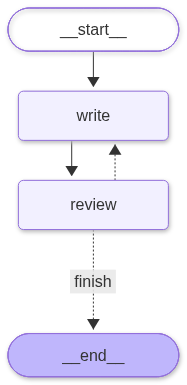

In [62]:
review_builder = StateGraph(ReviewState)

review_builder.add_node("write", write_draft)
review_builder.add_node("review", review_draft)

review_builder.add_edge(START, "write")
review_builder.add_edge("write", "review")
review_builder.add_conditional_edges("review", review_route, {"write": "write", "finish": END})

review_graph = review_builder.compile()
review_graph

![위 코드 실행 흐름](./images/ref/02_02.png)

위에서 만든거 글자를 보내서 실행

In [63]:
review_result = review_graph.invoke({
    "topic": "RAG", 
    "draft": "", 
    "feedback": "", 
    "approved": False, 
    "attempts": 0
})

print(review_result)

{'topic': 'RAG', 'draft': 'RAG은 중요한 개념입니다. 예시: 사용자의 질문을 검색하고 근거를 붙여 답합니다.', 'feedback': '통과', 'approved': True, 'attempts': 2}


이제 필드로 만들고, ...

In [64]:
from pydantic import BaseModel, Field

In [65]:
# 초안 평가를 위한 데이터 모델 정의
class DraftGrade(BaseModel):
    score: int = Field(ge=0, le=5, description="정확성/구체성 기준 0~5점")
    strengths: str = Field(description="잘된 점")
    weaknesses: str = Field(description="부족한 점")
    revision_instrunction: str = Field(description="다음 수정 지시")

In [66]:
# LLM 객체가 정상적으로 생성되었는지 확인
if llm is not None:
    # LLM이 DraftGrade 형식으로 결과를 반환하도록 설정
    grader = llm.with_structured_output(DraftGrade)

    # 평가할 초안 준비
    sample_draft = "RAG는 문서를 찾아 답변을 만드는 방법이니다."

    # LLM에 초안 평가 요청
    # 정확성, 예시, 주의사항을 기준으로 검토
    grade = grader.invoke("다음 설명을 초보자용 교재 기준으로 평가하세요. 정확성, 예시, 주의사항을 확힌하세요.\n" + sample_draft)

    # Pydantic 객체를 딕셔너리로 변환하여 출력
    print(grade.model_dump())
else:
    print("LLM이 초기화되지 않았습니다.")

{'score': 2, 'strengths': 'RAG가 문서 검색과 답변 생성을 결합한다는 핵심 방향은 간단히 담고 있습니다. 초보자가 RAG의 기본 개념을 처음 접할 때 출발점으로 사용할 수 있습니다.', 'weaknesses': '오탈자(‘방법이니다’)가 있습니다. 또한 RAG는 단순히 ‘문서를 찾아 답변을 만드는 방법’이라기보다, 외부 문서나 지식 저장소에서 관련 정보를 검색(Retrieval)한 뒤 그 내용을 언어 모델에 제공하여 답변을 생성(Generation)하는 구조 또는 기법입니다. 검색된 문서가 항상 정확하거나 관련성이 높은 것은 아니며, 모델이 문서에 없는 내용을 만들어낼 수 있다는 주의사항도 빠져 있습니다. 구체적인 예시가 없어 초보자가 작동 방식을 이해하기 어렵습니다.', 'revision_instrunction': '다음처럼 수정하세요: ‘RAG(Retrieval-Augmented Generation)는 외부 문서나 데이터베이스에서 질문과 관련된 정보를 검색한 뒤, 검색 결과를 참고하여 언어 모델이 답변을 생성하는 방법입니다. 예를 들어 회사 규정 문서에서 휴가 규정을 찾아 그 내용을 바탕으로 직원의 질문에 답할 수 있습니다. 단, 검색 결과의 품질에 따라 답변의 정확성이 달라지며, 모델이 검색된 문서에 없는 내용을 잘못 생성할 수도 있으므로 출처와 답변을 확인해야 합니다.’'}


위 코드 설명

![코드셀 2개 요약](./images/ref/02_03.png)

#### **2-1. 기존 Reflection 그래프와 차이**
- **기존 `review_draft()`**: Python 조건문으로 `"예시:"` 포함 여부만 확인하여 통과 여부 결정
- **LLM 기반 `grader`**: LLM이 초안의 정확성, 장단점, 수정 방향까지 평가함

> 기존 방식은 **정해진 조건으로 평가**, LLM 방식은 **내용을 분석하고 구체적인 피드백을 생성**한다는 차이가 있음.

![차이 비교 이미지](./images/ref/02_04.png)

In [67]:
# 한번 더 출력
if llm is not None:
    original = "RAG는 검색을 합니다."
    feedback = "정의와 실제 예시, 한계점을 추가하세요."
    improved = llm.invoke(
        "당신은 AI 교육 교재 편집자입니다. 사실을 지어내지 마세요.\n"
        f"원문: {original}\n피드백: {feedback}\n수정본만 작성하세요."
    )
    print(improved.content)

RAG(Retrieval-Augmented Generation)는 외부 문서나 데이터베이스에서 관련 정보를 검색한 뒤, 검색 결과를 참고해 답변을 생성하는 방식입니다. 예를 들어 사내 규정 문서를 검색하여 “출장비 정산 기준”에 대한 질문에 관련 조항을 근거로 답할 수 있습니다. 다만 검색된 정보가 부정확하거나 최신이 아닐 수 있으며, 관련 문서를 찾지 못하면 답변의 정확도가 떨어질 수 있습니다. 또한 검색 결과에 없는 내용은 안정적으로 답하기 어렵고, 문서의 접근 권한과 개인정보 보호도 고려해야 합니다.


___
# **3. RAG**
- RAG(Retrieval-Augmented Generation)는 검색 기반 생성 모델을 의미함.
- 생성형 AI가 외부 지식을 검색해 답변을 생성하는 방식
- 단순히 모델 파라미터에 저장된 정보만으로 답변하지 않고, 관련 문서를 검색(Retrieval)한 뒤, 이것을 입력 맥락에 포함시켜 답변을 생성함
- 이 방식은 모델이 최신 정보나 도메인 특화 지식을 활용할 수 있게 해줌
- 그리고 환각(hallucination) 문제를 줄이는 데 도움을 줘, 신뢰도를 높임
- 예를 들어 고객 지원, 법률 문서 검색, 논문 요약 등에서 내부 데이터베이스에서 필요한 정보를 불러와 답변을 생성할 수 있음

![RAG란?](./images/ref/02_05.png)

### **3-1. 왜 이슈가 되었냐?**
    - llm만 이용하면 최신 정보나 도메인 특화 지식을 반영하기 어려움
    - 모델이 잘못된 정보를 생성할 가능성(환각) 존재
    - 따라서 외부 지식을 검색해 답변에 반영하는 RAG가 주목받음

### **3-2. RAG 워크플로우**
- 질문을 입력받은 뒤, 쿼리를 벡터로 변환해 벡터 DB에서 관련 문서를 겁색한 다음 이를 컨텍스트로 합쳐 LLM이 답변을 생성하는 단일 경로의 직선형 파이프라인임
- 검색과 생성이 고정된 순서로 연결되어 있어 빠르고 단순하며, FAQ나 사내 문서 QA처럼 명확한 질문/답변 작업에 적함함


### **3-3. 에이전텍 RAG 워크플로우**
- 기본 RAG 흐름 위에 에이전트의 자율성을 추가해 질문을 분석하고 필요할때만 검색하거나 쿼리를 재작성해 여러번 검색함
- 검색 결과를 평가/반성 후 재시도하는 반복형 파이프라인
- LLM이 언제 검색할지, 어떤 도구를 쓸지, 어떻게 답변을 다듬을지까지 스스로 결정함

> 복잡한 리서치, 멀티홉 질의, 장기 과제에 더 강력함!
```
    - 단일 홈(Single Hop): 하나의 문서/사실만 찾아도 바로 답 가능(단답으로 할 수 있는)
    - 멀티 홉(Multi Hop): 여러 정보원을 찾아 순차적으로 종합해야 답할 수 있음(추론이 필요한 경우)
        - 예: "삼성 회장이 좋아하는 음식이 뭐야?"
            1) 삼성 회장에 대한 정보 검색
            2) 삼성 회장이 좋아하는 음식 확인
            3) 답변 생성
            4) 필요시 추가 검색 및 확인 후 최종 답변 생성
```

### **3-4. RAG의 역할**
- 검색(Retrieval): 사용자가 질문한 내용과 관련된 정보를 외부 지식원에서 찾아오는 역할
- 증강(Augmentation): 검색된 정보를 바탕으로 질문에 대한 답변을 생성하거나 보완하는 역할
- 생성(Generation): 증강된 정보를 활용하여 최종 답변을 생성하는 역할

> RAG가 환각을 자동으로 없애진 않음

> 검색 실패, 오래된 문서, 잘못된 근거 연결, LLM의 근거 오류가 남을수도 있음

[spri-소프트웨어 정책 연구소](https://spri.kr/posts?code=AI-Brief) >> 여기에서 10월호 받아 사용함!

In [68]:
# pip install langchain_community
# pip install pypdf
from pathlib import Path
from langchain_community.document_loaders import PyPDFLoader

In [69]:
# pdf_candidates = sorted(Path.cwd().glob("SPRi*.pdf"))
pdf_candidates = sorted((Path.cwd() / "data").glob("SPRi*.pdf"))

print("현재 폴더:", Path.cwd())
print("발견된 PDF 파일:", [p.name for p in pdf_candidates])

현재 폴더: d:\OSA\14_에이전트
발견된 PDF 파일: ['SPRi AI Brief 2026년 10월호(2026-10-09).pdf']


In [70]:
import logging

# pypdf에서 발생하는 WARNING 로그 숨기기
logging.getLogger("pypdf").setLevel(logging.ERROR)

위 코드는 에러 로그 숨기는거임 (이미지 참고)

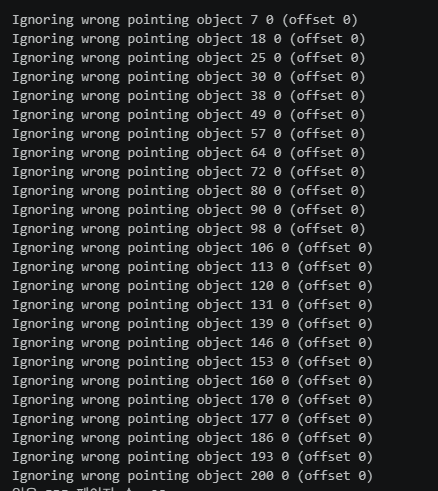

In [71]:
# PDF 파일 읽기 및 페이지 정보 출력
pdf_path = pdf_candidates[0]
pdf_pages = PyPDFLoader(pdf_path).load()

print("읽은 PDF 페이지 수:", len(pdf_pages))
print("첫 페이지의 메타데이터 내용:", pdf_pages[0].metadata)
print("PDF 5페이지의 일부:", pdf_pages[4].page_content[:500])

읽은 PDF 페이지 수: 28
첫 페이지의 메타데이터 내용: {'producer': 'macOS 버전 26.6.2(빌드 25G83) Quartz PDFContext', 'creator': '한글', 'creationdate': "D:20261009073006Z00'00'", 'moddate': "D:20261009073006Z00'00'", 'title': '무제', 'source': 'd:\\OSA\\14_에이전트\\data\\SPRi AI Brief 2026년 10월호(2026-10-09).pdf', 'total_pages': 28, 'page': 0, 'page_label': '1'}
PDF 5페이지의 일부: SPRi AI Brief
 2
0
2
6
년
  1
0
월
호
4
EU는 「AI 법」 본격 시행, 미국은 AI 규제 완화 기조 주도
328)287
EU 「AI 법」의 투명성 의무가 2026년 8월 2일 적용 개시되었고, EU 집행위원회는 범용 AI 모델 
의무 준수 여부를 확인하기 위해 전 세계 30여 개 범용 AI 모델 제공 기업에 정보 요청 전달 
미국은 G20 혁신 장관회의에서 특정 기술만을 겨냥한 신규 규제를 지양하는 '캐롤라이나 원칙'을 제
시하였고, G20 회원국은 합의한 장관 성명에서 이 원칙을 참고해 각국 정책 체계를 수립하기로 함
EU, 투명성 의무 적용 개시하고, 범용 AI 모델 의무 집행 개시
유럽연합(EU)의 포괄적 AI 규제 법인 「AI 법」의 투명성 의무가 2026년 8월 2일부터 적용 개시
이에 따라 AI 시스템 제공자와 배포자는 사용자가 AI와 상호작용하고 있음을 고지하고, AI 생성 콘텐츠에 
기계 판독 가능한 표시를 제공하며, 딥페이크 등


![아래 용어 설명](./images/ref/02_06.png)

- Chunk(청크): 긴 문서를 검색하기 쉬운 작은 조각으로 분할한 것. 너무 작으면 맥락이 끊기고, 너무 크면 잡음이 늘어남(= 불필요한 정보가 많아짐)
- Embedding(임베딩): 텍스트를 벡터로 변환한 표현, 벡터 DB에서 유사도 검색에 사용됨
- Vector DB(벡터 데이터베이스): 임베딩을 저장하고 유사한 벡터를 검색하는 시스템
- Retriever(리트리버 = 검색기): 질문을 받아 관련 문서 목록을 반환하는 인터페이스
- Overlap(겹침): 문장 경계에서 정보가 끊기는 현상 줄임. 저장량과 중복 결과 늘림(청크 간 겹침)

> 청크 기억하고 있기! 청크를 어떻게 나누냐에 따라 검색 성능과 결과의 품질이 달라짐(최프때 중요~!)

### 3-5.이제 청크 나누는거 해봄

청크를 나눌때 겹쳐서 잘라야함(그게 Overlap, 문장 경계에서 정보가 끊기는 현상 줄임)

예를 들어, 한 문서가 길다면 일정 길이로 나누되, 이전 청크의 일부를 다음 청크에 포함시켜야 함. 이렇게 하면 검색 시 중요한 정보가 잘리지 않고 유지됨.
```
'사과는 맛있다. 초록색 사과는 새콤하고, 빨간색 사과는 달다.'

라는 문장이 있을 때
청크를 잘못 나누면 중요한 정보가 잘릴 수 있음.
예를 들어 위 문장을 길이 10으로 나누고, 겹침을 5로 설정하지 않으면

'사과는 맛있다.'
'초록색 사과는 새콤하고, 빨간색 사과는 달다.'

이렇게 나뉘어 초록색 사과와 빨간색 사과에 대한 정보가 첫 번째 청크와 연결되지 않아 검색 시 놓칠 수 있음.
```

In [72]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

In [74]:
# RecursiveCharacterTextSplitter: 문단, 줄바꿈, 공백 등을 우선 고려해 분할하는 도구
pdf_splitter = RecursiveCharacterTextSplitter(chunk_size=600, chunk_overlap=100)
pdf_chunks = pdf_splitter.split_documents(pdf_pages)

for i, doc in enumerate(pdf_chunks):
    doc.metadata["doc_id"] = f'SPRi-{i:04d}'
    doc.metadata["page_display"] = int(doc.metadata.get("page", 0)) + 1
print("페이지: ", len(pdf_pages), "청크: ", len(pdf_chunks))

페이지:  28 청크:  86


In [75]:
for doc in pdf_chunks[:2]:
    print("ID: ", doc.metadata["doc_id"], "PDF 쪽: ", doc.metadata["page_display"])
    print(repr(doc.page_content[:200]))

ID:  SPRi-0000 PDF 쪽:  1
'10월호\nੋҕ\u0ad1\x01מ\u0891স\u0a44\x01୭न\x01زೱ'
ID:  SPRi-0001 PDF 쪽:  2
'Ἂк\x0b\x13ዞம⸺⺟ ∙ 2026년 9월 AI 모델 현황 2\n⁋⑻\n･\nᓋ⁒\n∙ EU는 「AI 법」 본격 시행, 미국은 AI 규제 완화 기조 주도 4\n∙미·중 정상, ‘초지능’ 대화와 소통 창구 구축 합의 5\n∙미국 의회, 잇단 AI 규제 발의에도 입법은 정체 6\n∙미국 사이버보안 합동 권고문, 대규모 지식 증류를 통한 모델 탈취 경고 7\n∙중국 최고인민법원, A'


### **3-6. metadata를 보존하는 이유**
- 검색 결과가 예를 들어 "EU AI 법의 투명성 의무"라고 말할 때 어느 페이지에서 나온 말인지 알아야 함
- doc_id는 검색 결과를 중복 제거하거나 평가할 때 사용하는 청크 ID
- page_display는 PDF 뷰어에서 볼 수 있는 1부터 시작하는 페이지 번호
    - 보고서 본문에 인쇄된 쪽수와 PDF 뷰어 쪽수는 표지/목차 등의 차이로 다를수도 있음! (그래서 이걸 파악하기 위해 page_display를 사용함)

![용어 설명](./images/ref/02_07.png)

- Vector Store: 청크화된 문서를 벡터로 변환하여 저장하는 공간
- BM25Retriever: 단어 기반 검색기(검색어와 문서의 단어 매칭을 통해 관련 문서를 찾음)
- Query: 사용자가 입력한 검색어(질문)
- Corpus: 검색 대상이 되는 문서들의 집합(말뭉치..)
- Candidate: 검색 결과로 선택된 문서들의 집합(검색어와 관련성이 높은 문서들 = 후보)

#### 리트리버 실습!

In [ ]:
# pip install rank_bm25
import re
from langchain_community.retrievers import BM25Retriever

In [79]:
def simple_tokens(text: str):
    return re.findall(r"[가-힣A-Za-z0-9]+", text.lower())

pdf_bm25 = BM25Retriever.from_documents(pdf_chunks, preprocess_func=simple_tokens)
pdf_bm25.k = 4 # 가져올 결과 개수
pdf_hits = pdf_bm25.invoke("Muse 개인용 AI 에이전트 기능")

for rank, doc in enumerate(pdf_hits, start=1):
    print(f"{rank}위 | PDF {doc.metadata['page_display']}쪽 | {doc.metadata['doc_id']}")
    print(doc.page_content[:200].replace("\n", " "))

1위 | PDF 13쪽 | SPRi-0038
328)287 메타가 이메일이나 캘린더, 결제 등 일상적으로 사용하는 앱과 서비스를 연동해 다양한  업무를 수행하는 개인용 AI 에이전트 ‘Muse’ 출시 Muse는 출시 후 첫 12일간 미국·캐나다 iOS 다운로드 수가 ChatGPT
2위 | PDF 2쪽 | SPRi-0001
Ἂкዞம⸺⺟ ∙ 2026년 9월 AI 모델 현황 2 ⁋⑻ ･ ᓋ⁒ ∙ EU는 「AI 법」 본격 시행, 미국은 AI 규제 완화 기조 주도 4 ∙미·중 정상, ‘초지능’ 대화와 소통 창구 구축 합의 5 ∙미국 의회, 잇단 AI 규제 발의에도 입법은 정체 6 ∙미국 사이버보안 합동 권고문, 대규모 지식 증류를 통한 모델 탈취 경고 7 ∙중국 최고인민법원, A
3위 | PDF 13쪽 | SPRi-0040
앱토피아(Apptopia)에 따르면 Muse는 출시 첫 12일간 미국·캐나다 iOS에서 180만 건이 다운로드 되어 ChatGPT(130만 건)를 앞섰으며, 같은 기간 전 세계 누적 설치 수는 280만 건을 기록 미국 매체 악시오스(Axios)에 따르면 최근 스타트업과 빅테크가 잇달아 개인용 에이전트 서비스를  출시하며 관련 시장이 활성화 비공개 베타
4위 | PDF 14쪽 | SPRi-0042
328)287 중국 스마트폰 제조사 오포와 비보, 아너가 각각 AI 에이전트에 앱과 개인정보, 기기 기능  접근 권한을 부여하는 신규 운영체제를 공개 3개 스마트폰 제조사가 발표한 신규


#### llm과 연결

In [ ]:
# pip install langchain_chroma

# OpenAIEmbeddings: 임베딩 모델 | 글자를 의미 비교에 쓸 숫자 배열로 바꿈 | PDF 청크 전체를 임베딩하면 API 호출 비용이 많이 발생할 수 있음
# Chroma: 벡터 데이터베이스 | 임베딩된 벡터와 문서 정보를 저장하고 비슷한 벡터를 검색하는 데이터베이스
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma

In [84]:
if OPENAI_API_KEY:
    # 이거 모델 OPENAI 사이트가면 모델 많음 -> 그 중 하나 쓴거임
    pdf_embedding_model = OpenAIEmbeddings(model="text-embedding-3-small")
    # 이렇게 저장해놨다가 필요하면 나중에 불러와서 검색 가능
    pdf_vectorstore = Chroma.from_documents(documents=pdf_chunks, embedding=pdf_embedding_model, collection_name="spri_ai_brief_202610")
    # 검색할 때 상위 k개의 결과를 가져오도록 설정
    # as_retriever: 벡터 저장소를 리트리버 방식으로 사용할 수 있게 변환
    pdf_vector_retriever = pdf_vectorstore.as_retriever(search_kwargs={"k": 4})
    # 넣을 질문
    pdf_vector_hits = pdf_vector_retriever.invoke("개인 비서가 이메일과 일정 관리를 돕는다는 내용")

    for doc in pdf_vector_hits:
        print(f"PDF {doc.metadata['page_display']}쪽 | {doc.page_content[:120]}")

else:
    print("OPENAI_API_KEY가 설정되지 않았습니다.")


PDF 14쪽 | 트에 앱과 개인정보, 기기 기능 접근 권한을 부여하며 AI를 운영체제에 심층 통합하는 단계에 진입
AI 모델이 복잡한 작업을 계획하고 조율하며 완수하도록 돕는 소프트웨어 계층인 ‘하네스(Harness)’를 
핵심 
PDF 13쪽 | SPRi AI Brief
 2
0
2
6
년
  1
0
월
호
12
메타, 개인용 AI 에이전트 ‘Muse’ 출시
328)287
메타가 이메일이나 캘린더, 결제 등 일상적으로 사용하는 앱과 서비스를 연동해 
PDF 13쪽 | 앱토피아(Apptopia)에 따르면 Muse는 출시 첫 12일간 미국·캐나다 iOS에서 180만 건이 다운로드
되어 ChatGPT(130만 건)를 앞섰으며, 같은 기간 전 세계 누적 설치 수는 280만 건을 기록

PDF 8쪽 | 구독 대비 사용량 비율, 신규 계정의 실시간 최대 사용량, 기업 규모의 처리량 패턴도 모니터링 필요
두 번째는 맞춤형 대응 변경 사항 배포로, 악의적 증류 시도가 의심되면 응답 방식을 변경해 증류 활동 제한
세 


위 두가지 내용 뽑아온거 결과 조금 다른데 어떻게 다른지 확인해보기!

### BM25와 벡터 Retriever 비교
- BM25: 단어가 정확히 들어간 문제를 찾는 데 강함
- 벡터 검새: 다른 표현을 써도 관련된 문서를 찾을 가능성이 높음
- 둘 다 틀린 문서를 가져올 수 있으므로 검색 결과를 직접 검토해야함
- 검색된 4개 문서가 모두 답변에 필요한 근거인것 아님! Top-K는 개수 제한이지 정답 보장이 아님